# SafeStep · 5 — Fall direction · fall situation · pre-impact warning · long-lie
Same subject split, tuned on validation, reported once on test. Uses the **274 phone-ready features**.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os, sys, json, time, shutil, warnings
import numpy as np, pandas as pd, joblib
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import f1_score, confusion_matrix, average_precision_score, balanced_accuracy_score
warnings.filterwarnings('ignore')
BASE = '/content/drive/MyDrive/Daffodil Robo Tech Olympiad'
PROJ = f'{BASE}/SafeStep'
D = {k: f'{PROJ}/{k}' for k in ['data', 'artifacts', 'figures', 'models', 'code']}
DEPLOY = f"{D['models']}/deploy"; os.makedirs(DEPLOY, exist_ok=True)
sys.path.insert(0, D['code']); import safestep_core as core
SEED = 42; rng = np.random.default_rng(SEED)
sns.set_theme(style='whitegrid'); plt.rcParams['figure.dpi'] = 110
def save_fig(name): plt.savefig(f"{D['figures']}/{name}.png", dpi=300, bbox_inches='tight')
FS, W = core.FS, core.WIN
F    = pd.read_parquet(f"{D['data']}/features_345.parquet").set_index('win_id')
wm   = pd.read_parquet(f"{D['data']}/windows_meta.parquet").set_index('win_id')
meta = pd.read_parquet(f"{D['data']}/trials_meta.parquet").set_index('trial_id')
SEL  = json.load(open(f"{D['artifacts']}/feature_selection.json"))
CFG  = json.load(open(f"{DEPLOY}/deploy_config.json"))
try:
    import lightgbm as lgb
    def make_model(): return lgb.LGBMClassifier(n_estimators=400, learning_rate=0.05, num_leaves=63, subsample=0.8, subsample_freq=1,
                                                colsample_bytree=0.8, class_weight='balanced', n_jobs=-1, random_state=SEED, verbose=-1)
except ImportError:
    def make_model(): return ExtraTreesClassifier(n_estimators=400, min_samples_leaf=2, class_weight='balanced', n_jobs=-1, random_state=SEED)
print(F.shape, '| deployed fall model:', CFG['fall_model'], '| activity model:', CFG['activity_model'])

(136051, 345) | deployed fall model: MLP | activity model: LightGBM


In [3]:
class Streamer:
    """slides over whole recordings of one split, scores alarms like the live app."""
    def __init__(self, split, ages=None):
        sub = wm[wm.split == split].sort_values(['trial_id', 'start'])
        if ages: sub = sub[sub.age_group.isin(ages)]
        self.win_ids = sub.index.values
        local = {w: i for i, w in enumerate(sub.index)}
        self.trials = []
        for tid, g in sub.groupby('trial_id', sort=False):
            r = meta.loc[tid]
            self.trials.append(dict(tid=tid, rows=np.array([local[w] for w in g.index]), starts=g.start.values,
                                    t_end=(g.start.values + W) / FS, impact=r.peak_idx / FS if r.type == 'Fall' else None,
                                    type=r.type, code=r.code, age=r.age_group, hours=r.duration_s / 3600))
    @staticmethod
    def alarms(p, t_end, thr, k, refractory=10.0):
        hit = p >= thr
        if k > 1: hit = np.convolve(hit.astype(int), np.ones(k, int), 'full')[:len(hit)] >= k
        out, last = [], -1e9
        for t in t_end[hit]:
            if t - last >= refractory: out.append(t); last = t
        return out
    def evaluate(self, p, thr, k=1, ages=None):
        caught = n_fall = fa = 0; hours = 0.0; delays = []
        for tr in self.trials:
            if ages and tr['age'] not in ages: continue
            al = self.alarms(p[tr['rows']], tr['t_end'], thr, k)
            if tr['type'] == 'Fall':
                n_fall += 1; ok = [a for a in al if tr['impact'] <= a <= tr['impact'] + W / FS + 0.5]
                caught += bool(ok)
                if ok: delays.append(ok[0] - tr['impact'])
            else:
                fa += len(al); hours += tr['hours']
        return dict(sensitivity=caught / max(n_fall, 1) if n_fall else np.nan, fa_per_hour=fa / max(hours, 1e-9) if hours else np.nan,
                    false_alarms=fa, falls=n_fall, adl_hours=hours, median_delay=float(np.median(delays)) if delays else np.nan)

GRID = np.r_[np.linspace(0.05, 0.95, 19), 0.97, 0.98, 0.99]
def tune(st, p, fa_target=1.0, ks=(1, 2)):
    best = None
    for k in ks:
        for thr in GRID:
            r = st.evaluate(p, thr, k)
            key = (r['fa_per_hour'] <= fa_target, r['sensitivity'], -r['fa_per_hour'])
            if best is None or key > best[0]: best = (key, dict(thr=float(thr), k=k, **r))
    return best[1]

In [4]:
FEAT = SEL['clean_phone']
def fit_cached(name, Xi, y):
    p = f"{D['models']}/extra_{name}.joblib"
    if os.path.exists(p): return joblib.load(p)
    t0 = time.time(); m = make_model().fit(F[FEAT].values[Xi], y); joblib.dump(m, p, compress=3)
    print(f'fitted {name} on {len(Xi)} windows in {time.time()-t0:.0f}s'); return m
RESULTS = {}
print(len(FEAT), 'features')

274 features


## 1 · Fall direction & fall situation (impact windows)

fitted direction on 4192 windows in 55s
direction val F1 0.652 | test F1 0.589 | test per-fall accuracy 74.0%


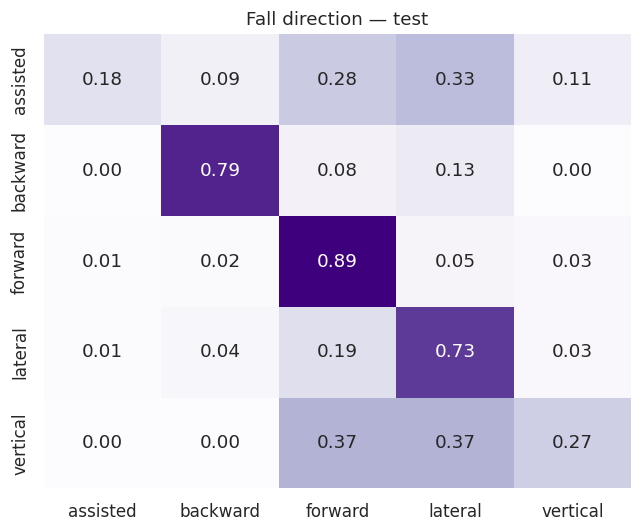

fitted context on 4192 windows in 50s
context   val F1 0.738 | test F1 0.691 | test per-fall accuracy 75.8%


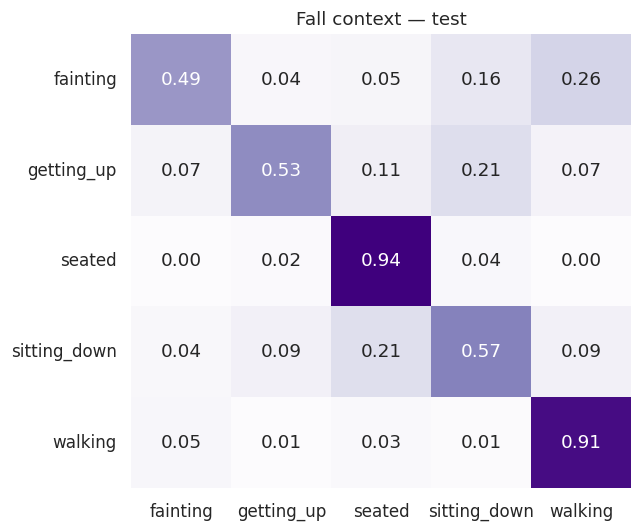

In [5]:
MODELS5 = {}
for task, col in [('direction', 'y_direction'), ('context', 'y_context')]:
    idx = {s: np.where(((wm.split == s) & (wm[col] != 'ignore')).values)[0] for s in ['train', 'val', 'test']}
    y = {s: wm[col].values[i] for s, i in idx.items()}
    m = fit_cached(task, idx['train'], y['train']); MODELS5[task] = m
    res = {}
    for s in ['val', 'test']:
        P = m.predict_proba(F[FEAT].values[idx[s]]); pred = m.classes_[P.argmax(1)]
        res[f'{s}_f1'] = f1_score(y[s], pred, average='macro')
        # one decision per fall: average the impact windows of that recording
        g = pd.DataFrame(P, columns=m.classes_).assign(tid=wm.trial_id.values[idx[s]], true=y[s]).groupby('tid')
        tp = g[list(m.classes_)].mean().idxmax(axis=1); tt = g.true.first()
        res[f'{s}_trial_acc'] = float((tp == tt).mean())
    RESULTS[task] = dict(classes=list(m.classes_), **res)
    print(f"{task:9s} val F1 {res['val_f1']:.3f} | test F1 {res['test_f1']:.3f} | test per-fall accuracy {res['test_trial_acc']:.1%}")
    pred = m.classes_[m.predict_proba(F[FEAT].values[idx['test']]).argmax(1)]
    cm = confusion_matrix(y['test'], pred, labels=m.classes_, normalize='true')
    plt.figure(figsize=(6, 5)); sns.heatmap(cm, annot=True, fmt='.2f', cmap='Purples', xticklabels=m.classes_, yticklabels=m.classes_, cbar=False)
    plt.title(f'Fall {task} — test'); plt.tight_layout(); save_fig(f'50_{task}_confusion'); plt.show()

## 2 · Pre-impact warning (detect the fall while it is happening)

fitted preimpact on 56637 windows in 38s
threshold 0.25 | test: 92.0% of falls warned BEFORE impact | median lead 520 ms | 2.36 false warnings/h


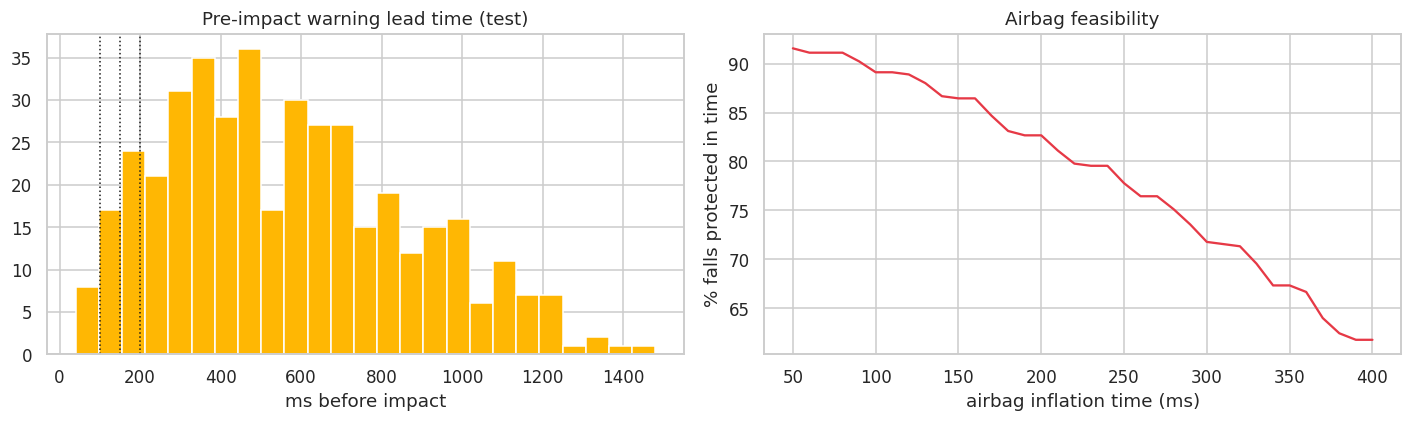

In [6]:
t_end = wm.t_end_rel_impact.values
y_pre = np.select([(wm.type == 'Fall') & (t_end >= -0.6) & (t_end <= -0.05), wm.phase == 'adl',
                   (wm.phase == 'pre_fall') & (t_end < -1.5)], [1, 0, 0], -1)
itr = np.where((wm.split == 'train').values & (y_pre >= 0))[0]
m_pre = fit_cached('preimpact', itr, y_pre[itr]); MODELS5['preimpact'] = m_pre

def lead_eval(st, p, thr):
    leads, fa, hours, n = [], 0, 0.0, 0
    for tr in st.trials:
        al = np.array(st.alarms(p[tr['rows']], tr['t_end'], thr, 1, refractory=5.0))
        if tr['type'] == 'Fall':
            n += 1; e = al[(al < tr['impact']) & (al >= tr['impact'] - 1.5)] if len(al) else al
            leads.append((tr['tid'], tr['code'], tr['age'], (tr['impact'] - e.min()) * 1000 if len(e) else np.nan))
        else:
            fa += len(al); hours += tr['hours']
    L = pd.DataFrame(leads, columns=['tid', 'code', 'age', 'lead_ms'])
    return dict(warned=float(L.lead_ms.notna().mean()), fa_h=fa / max(hours, 1e-9), median_lead_ms=float(L.lead_ms.median())), L

ST = {s: Streamer(s) for s in ['val', 'test']}
pv = m_pre.predict_proba(F.loc[ST['val'].win_ids, FEAT].values)[:, 1]
pt = m_pre.predict_proba(F.loc[ST['test'].win_ids, FEAT].values)[:, 1]
best = None
for thr in GRID:
    r, _ = lead_eval(ST['val'], pv, thr)
    key = (r['fa_h'] <= 2.0, r['warned'], -r['fa_h'])
    if best is None or key > best[0]: best = (key, thr, r)
PRE_THR = float(best[1])
rt, LEAD = lead_eval(ST['test'], pt, PRE_THR)
RESULTS['preimpact'] = dict(thr=PRE_THR, val_warned=best[2]['warned'], val_fa_h=best[2]['fa_h'],
                            test_warned=rt['warned'], test_fa_h=rt['fa_h'], test_median_lead_ms=rt['median_lead_ms'])
print(f"threshold {PRE_THR:.2f} | test: {rt['warned']:.1%} of falls warned BEFORE impact | median lead {rt['median_lead_ms']:.0f} ms | {rt['fa_h']:.2f} false warnings/h")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].hist(LEAD.lead_ms.dropna(), bins=25, color='#ffb703'); ax[0].set_xlabel('ms before impact'); ax[0].set_title('Pre-impact warning lead time (test)')
for ms in [100, 150, 200]: ax[0].axvline(ms, color='k', ls=':', lw=1)
inf = np.arange(50, 401, 10); ax[1].plot(inf, [(LEAD.lead_ms >= i).mean() * 100 for i in inf], color='#e63946')
ax[1].set_xlabel('airbag inflation time (ms)'); ax[1].set_ylabel('% falls protected in time'); ax[1].set_title('Airbag feasibility')
plt.tight_layout(); save_fig('51_preimpact_lead'); plt.show()

## 3 · Long-lie: does the activity model recognise lying after a fall?

post_fall_recognised             0.967
normal_lying_called_after_fall   0.029
confirmed_share                  0.991
median_confirm_s                 3.500


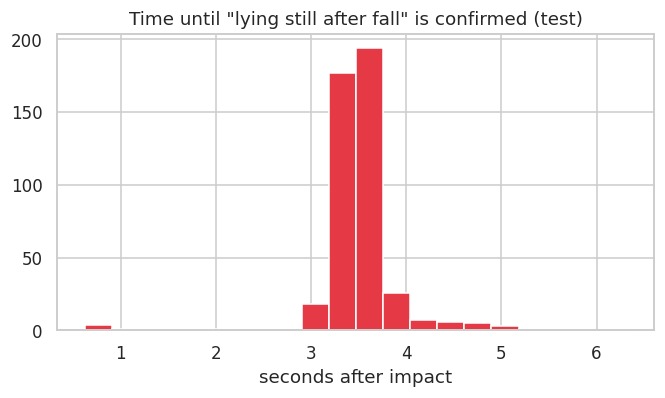

In [7]:
act = joblib.load(f"{DEPLOY}/activity_model.joblib"); classes = np.array(CFG['activity_classes'])
te = wm[wm.split == 'test']
pred = pd.Series(classes[act.predict_proba(F.loc[te.index, CFG['features']].values).argmax(1)], index=te.index)
post = te.phase == 'post_fall'
lying_adl = te.code.isin(['D12', 'D13', 'D14'])
confirm = []
for tid, g in te[te.type == 'Fall'].groupby('trial_id'):
    imp = meta.loc[tid, 'peak_idx'] / FS; g = g.sort_values('start')
    lab = pred.loc[g.index].values; tend = (g.start.values + W) / FS
    run = 0; t_c = np.nan
    for l, t in zip(lab, tend):
        run = run + 1 if (t > imp and l in ('Lying after fall', 'Lying')) else 0
        if run >= 2: t_c = t - imp; break
    confirm.append(t_c)
confirm = np.array(confirm)
RESULTS['long_lie'] = dict(post_fall_recognised=float(pred[post].isin(['Lying after fall', 'Lying']).mean()),
                           normal_lying_called_after_fall=float((pred[lying_adl] == 'Lying after fall').mean()),
                           confirmed_share=float(np.isfinite(confirm).mean()), median_confirm_s=float(np.nanmedian(confirm)))
for k, v in RESULTS['long_lie'].items(): print(f'{k:32s} {v:.3f}')
plt.figure(figsize=(7, 3.5)); plt.hist(confirm[np.isfinite(confirm)], bins=20, color='#e63946')
plt.xlabel('seconds after impact'); plt.title('Time until "lying still after fall" is confirmed (test)'); save_fig('52_long_lie'); plt.show()

## 4 · Save for the app

In [8]:
for k, m in MODELS5.items(): joblib.dump(m, f'{DEPLOY}/{k}_model.joblib', compress=3)
json.dump({'features': FEAT, 'direction': {'classes': RESULTS['direction']['classes']},
           'context': {'classes': RESULTS['context']['classes']}, 'preimpact': {'thr': PRE_THR}},
          open(f'{DEPLOY}/extra_config.json', 'w'), indent=2)
json.dump(RESULTS, open(f"{D['artifacts']}/extra_results.json", 'w'), indent=2, default=float)
LEAD.to_csv(f"{D['artifacts']}/preimpact_lead.csv", index=False)
pd.json_normalize(RESULTS, sep='.').T.rename(columns={0: 'value'})

,value
direction.classes,"[assisted, backward, forward, lateral, vertical]"
direction.val_f1,0.652042
direction.val_trial_acc,0.77
direction.test_f1,0.58898
direction.test_trial_acc,0.74
context.classes,"[fainting, getting_up, seated, sitting_down, w..."
context.val_f1,0.737798
context.val_trial_acc,0.793333
context.test_f1,0.691415
context.test_trial_acc,0.757778
